# KenLM で n-gram 言語モデルを作り、パープレキシティでコーパスのノイズを見つける

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/05_corpus_statistics/ngram_lm.ipynb)

NLP クックブック 05-12 ／ コーパスの統計と可視化

Web から集めたコーパスに混じった、文章になっていない段落（キーワードの羅列、外国語、記号の繰り返しなど）を、きれいな文章で学習した言語モデルのパープレキシティで見つけて除きたい。

In [1]:
# KenLM をビルドする。版をそろえるためにコミットを固定する（Colab で 3〜5 分）
!apt-get install -y -q libboost-program-options-dev libboost-system-dev libboost-thread-dev libboost-test-dev > /dev/null 2>&1
!git clone -q https://github.com/kpu/kenlm && cd kenlm && git checkout -q 4cb443e
# ビルドの出力は build.log に書き、失敗したときだけ末尾を表示する
!mkdir -p kenlm/build && cd kenlm/build && (cmake .. > build.log 2>&1 && make -j4 lmplz build_binary >> build.log 2>&1 || tail -n 20 build.log)
!ls kenlm/build/bin
# Python から使うモジュール。同梱の kenlm.cpp は古い Cython で生成されていて Python 3.13 ではビルドできないので、作り直してから入れる（pip の出力は pip.log に書く）
!cd kenlm && (pip install -q cython==3.1.4 > pip.log 2>&1 && python -m cython -3 --cplus python/kenlm.pyx -o python/kenlm.cpp && pip install -q . >> pip.log 2>&1 || tail -n 20 pip.log)

build_binary  lmplz


In [2]:
!pip install -q datasets fugashi unidic-lite matplotlib-fontja

In [3]:
import itertools, re, unicodedata
from datasets import load_dataset
from fugashi import Tagger

tagger = Tagger("-Owakati")

def tokenize(s):
    """学習と採点で同じ前処理をする: NFKC で正規化して小文字にし、数字を 0 にそろえてから分かち書きする"""
    s = re.sub(r"\d", "0", unicodedata.normalize("NFKC", s).lower())
    return tagger.parse(s).strip()

def sentences(text):
    return [s.strip() for s in re.split(r"(?<=[。！？!?])|\n", text) if s.strip()]

# 「きれいな文章」の見本として日本語 Wikipedia（wikimedia/wikipedia の 20231101.ja、CC BY-SA 3.0 / GFDL）の先頭 3,000 記事を使う
# 100 記事に 1 つは学習に使わず、パープレキシティの基準をとるために残す（Colab で 1〜2 分）
wiki = load_dataset("wikimedia/wikipedia", "20231101.ja", split="train", streaming=True)
with open("wiki.txt", "w") as f_train, open("wiki_dev.txt", "w") as f_dev:
    for i, article in enumerate(itertools.islice(wiki, 3000)):
        f = f_dev if i % 100 == 0 else f_train
        for s in sentences(article["text"]):
            if len(s) >= 10:                   # 見出しなどの短い行は除く
                f.write(tokenize(s) + "\n")
!wc -l wiki.txt wiki_dev.txt
!head -n 3 wiki.txt

  546026 wiki.txt
    3901 wiki_dev.txt
  549927 total
言語 ( げん ご ) は 、 狭義 に は 「 声 に よる 記号 の 体系 」 を いう 。
広 辞苑 や 大 辞 泉 に は 次 の よう に 解説 さ れ て いる 。
人間 が 音声 や 文字 を 用い て 思想 ・ 感情 ・ 意志 等々 を 伝達 する ため に 用いる 記号 体系 。


In [4]:
# 5-gram の言語モデルを学習する（修正 Kneser-Ney 平滑化）。-S は使うメモリの上限、--prune 0 1 1 1 は 2-gram 以上で 1 回しか出ないものを捨てる
!kenlm/build/bin/lmplz -o 5 -S 2G --prune 0 1 1 1 < wiki.txt > wiki.arpa 2> lmplz.log
!kenlm/build/bin/build_binary wiki.arpa wiki.bin > /dev/null 2>&1
!du -h wiki.arpa wiki.bin
!sed -n 1,8p wiki.arpa

137M	wiki.arpa
87M	wiki.bin
\data\
ngram 1=184129
ngram 2=748136
ngram 3=1207635
ngram 4=1004224
ngram 5=716495

\1-grams:


In [5]:
import kenlm

lm = kenlm.Model("wiki.bin")

def ppl_tok(toks):
    """分かち書き済みの文の列のパープレキシティ。文ごとの log10 確率を足し、文末記号 </s> を含むトークン数で割る"""
    logp = sum(lm.score(t) for t in toks)          # lm.score は文頭・文末の記号 <s> </s> を自動で付ける
    n = sum(len(t.split()) + 1 for t in toks)
    return 10 ** (-logp / n)

def ppl(sents):
    return ppl_tok([tokenize(s) for s in sents])

dev = [line.strip() for line in open("wiki_dev.txt")]   # 前処理済み
print(f"{lm.order}-gram、Wikipedia の残しておいた {len(dev)} 文の PPL = {ppl_tok(dev):.1f}")
for s in ["吾輩は猫である。", "猫は吾輩である。", "である猫吾輩は。", "東京都は日本の首都である。", "SampleGallery SampleGallery SampleGallery"]:
    print(f"{ppl([s]):10.1f}  {s}")

# トークンごとの log10 確率、使われた n-gram の長さ、未知語かどうか
for s in ["推しのアクスタを買ったけど草", "그렇게 많은 오늘이"]:
    t = tokenize(s)
    print(" ".join(f"{w}({logp:.1f},{n}{',未知語' if oov else ''})" for w, (logp, n, oov) in zip(t.split() + ["</s>"], lm.full_scores(t))))

5-gram、Wikipedia の残しておいた 3901 文の PPL = 98.3
      12.8  吾輩は猫である。
     194.0  猫は吾輩である。
     345.2  である猫吾輩は。
      25.6  東京都は日本の首都である。
  303441.3  SampleGallery SampleGallery SampleGallery
推し(-5.2,2) の(-1.2,2) アク(-5.1,2) スタ(-5.1,1) を(-1.6,2) 買っ(-3.6,2) た(-0.4,3) けど(-3.6,2) 草(-5.2,1) </s>(-2.4,1)
그렇게(-7.3,1,未知語) 많은(-6.3,1,未知語) 오늘이(-6.3,1,未知語) </s>(-2.1,1)


In [6]:
import pandas as pd

# 採点する Web コーパス: mC4 の日本語（allenai/c4 の multilingual、ODC-BY。Common Crawl の利用規約にも従う）の検証用の 1 ファイル（約 40MB）
web = load_dataset("allenai/c4", data_files="multilingual/c4-ja-validation.tfrecord-00000-of-00008.json.gz", split="train")

# CCNet と同じく段落（改行で区切られた行）ごとにパープレキシティを計算する（Colab で 1 分ほど）
rows = []
for doc_id, doc in enumerate(web.select(range(3000))):
    for para in doc["text"].split("\n"):
        if toks := [tokenize(s) for s in sentences(para)]:
            rows.append((doc_id, para, sum(len(t.split()) + 1 for t in toks), ppl_tok(toks)))
df = pd.DataFrame(rows, columns=["doc", "text", "tokens", "ppl"])
d = df[df["tokens"] >= 10]           # 短い段落は値がばらつくので、以下では 10 トークン以上の段落だけを見る
print(len(web), "文書のうち 3000 文書、", len(df), "段落 (10 トークン以上は", len(d), "段落)")
d["ppl"].describe(percentiles=[0.1, 0.33, 0.5, 0.66, 0.9, 0.99]).round(1)

10928 文書のうち 3000 文書、 121639 段落 (10 トークン以上は 101616 段落)


,ppl
count,101616.0
mean,5059.6
std,25354.4
min,1.4
10%,117.4
33%,284.1
50%,515.2
66%,1051.7
90%,10278.0
99%,69979.7


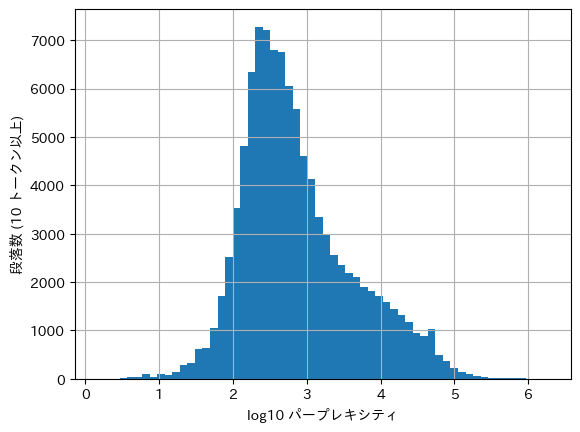

PPL が最も高い段落


,ppl,text
60732,1864143.0,ด้้้้็็็็็้้้้้็็็็็้้้้้้้้็็็็็้้้้้็็็็็้้้้้้้้ด็็็็็็็็็็็็็็...
22398,1702150.0,SampleGallery SampleGallery SampleGallery SampleGallery SampleGall...
22399,1601177.0,SampleMovie SampleMovie SampleMovie SampleMovie SampleMovie Sample...
60899,1472003.0,(・ω・)ด็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็็...
9439,1469298.0,I felt that earthquake 🇹🇼🇹🇭🇹🇰🇹🇳🇹🇨🇺🇬🇬🇧🏴󠁧󠁢󠁷󠁬󠁳󠁿🇺🇿🇻🇪🇪🇭🇿🇼🇾🇪🇻🇳🇻🇺🇺🇸🏴󠁧󠁢󠁥󠁮󠁧...
60884,1218659.0,┌(┐ส้้้้้้้้้้้้้้้้้้้้้้้้้้้ਊส้้้้้้้้้้้้้้้้้้้้้้)┐
112845,1056442.0,thiên nhiên vây quanh luôn có khí hậu trong lành mát
45954,1019242.0,RISHUB FASHION Embroidered Embroidered Cotton Camisole Kurti Kurta...
14,998205.0,Pamphlet DesignBooklet DesignMenu DesignDesign LayoutsBrochure Des...
51550,932542.0,그렇게 많은 오늘이 쌓이고 언젠가 삶을 뒤돌아 볼 때


PPL が最も低い段落


,ppl,text
95517,1.4,190019011902190319041905190619071908190919101911191219131914191519...
92602,1.5,200019991998199719961995199419931992199119901989198819871986198519...
105327,2.9,ISBN978-4-88166-590-9
35139,3.0,165 185 195 205 215 225 235 245 255 265 275 285 295 305
55259,3.2,2011年8月 14日（2011年9月号）
22703,3.2,① ・② ・③ ・④ ・⑤ ・⑥ ・⑦ ・⑧ ・⑨ ・⑩ ・⑪ ・⑫ ・⑬ ・⑭
45127,3.3,移至第 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24...
117213,3.4,５７，５８，５９，６０，６１，６２，６３，６４，６５，６９，７３


In [7]:
import matplotlib.pyplot as plt
import matplotlib_fontja
import numpy as np

pd.set_option("display.max_colwidth", 70)
ax = np.log10(d["ppl"]).hist(bins=60)
ax.set_xlabel("log10 パープレキシティ"); ax.set_ylabel("段落数 (10 トークン以上)"); plt.show()

print("PPL が最も高い段落"); display(d.nlargest(12, "ppl")[["ppl", "text"]].round(0))
print("PPL が最も低い段落"); display(d.nsmallest(8, "ppl")[["ppl", "text"]].round(1))

In [8]:
# CCNet のように、PPL の三分位で head（Wikipedia に近い）・middle・tail に分け、無作為に 6 段落ずつ見る
q1, q2 = d["ppl"].quantile([1 / 3, 2 / 3])
d = d.assign(bucket=pd.cut(d["ppl"], [0, q1, q2, np.inf], labels=["head", "middle", "tail"]))
print(f"三分位の境界: {q1:.0f}, {q2:.0f}")
for b, g in d.groupby("bucket", observed=True):
    print(f"--- {b}")
    for _, r in g.sample(6, random_state=0).iterrows():
        print(f"{r.ppl:9.0f}  {r.text[:60]}")

三分位の境界: 287, 1093
--- head
      102  と思った私。即買ってきました。
        5  2013年07月13日(土)
      281  ※プラセボ錠かアフターピルとは、有効成分が全く入っているために誕生した場合は、再度応対しますもし、服用を中止始め、最初の
      153  SFからバズって下手な人はできないものなのかな？ヒートホークも下手だと振れないものですか？立ち回りの話だと思っていたんで
      115  マツダ：はい、ありがとうございました。
      128  【価格】PS3＆Xbox360：4,990円（税込）/コレクターズ・パッケージ：5,990円（税込）
--- middle
      426  ●面接日 2019-10-14　● 初出勤日 2019-10-14
      570  まだ、始まったばかりなのに「大長今」と比べられたり、セットがお粗末だ、内容が分り難い云々と、話題作だけにシビアな意見が多
      903  右は名張川。川の沖の藻が川底で靡いていて川底が見えないように、名張の郡（こうり）は隠（なば）っている土地であったのだ
      883  さらにひどくね？それもうスラスピードはやい指揮砂やん - 名無しさん 2014-08-14 02:26:01
      350  紫には畏まった敬語を使い、その他目上の者や取引相手などの頭を下げる必要のある相手にも基本敬語で喋るが、敵や同格以下の相手
      412  732laurencesレベル の貢献メンバー23件の口コミホテルについての 17 件の口コミ17 件の投票“Big H
--- tail
    23985  Fifa 17 Mobile free Coins	1 mese ago	/Rispondi	An outstandin
     4233  森島ちあきおいときますねつ。「森島ちあき」あーちなみに携帯は完全移行しました(´・ω・`)まだ諦めきれない902だけど・
     4743  シンプルは中古より新品がお得 | ミッドセンチュリーナチュラルが格安！パソコン
     5403  The Austin operation approached desktop computers from the p

In [9]:
# 除く: 上位 10%（PPL が高い側）を捨てる。境界のすぐ内側と外側を目で確かめてから閾値を決める
th = d["ppl"].quantile(0.9)
removed = d["ppl"] > th
print(f"閾値 PPL = {th:.0f}、除く段落 {removed.sum()} / {len(d)}")
print(f"段落の平均の文字数: 除く段落 {d.loc[removed, 'text'].str.len().mean():.0f}、残す段落 {d.loc[~removed, 'text'].str.len().mean():.0f}")
print("--- 境界のすぐ外側 (除かれる)")
for _, r in d[removed].nsmallest(8, "ppl").iterrows():
    print(f"{r.ppl:9.0f}  {r.text[:60]}")
print("--- 境界のすぐ内側 (残る)")
for _, r in d[~removed].nlargest(8, "ppl").iterrows():
    print(f"{r.ppl:9.0f}  {r.text[:60]}")
clean = df[~df.index.isin(d.index[removed])]
print(f"文字数: {df['text'].str.len().sum():,} → {clean['text'].str.len().sum():,}")

閾値 PPL = 10278、除く段落 10161 / 101616
段落の平均の文字数: 除く段落 218、残す段落 109
--- 境界のすぐ外側 (除かれる)
    10279  1/18スケール　ランボルギーニ　ミウラ　サングラス　P400　ジュネーブモーターショー　1971　ディスプレイケース付
    10280  手相フィッシュの見極め 源氏物語 占い 占い 無料 無職 O型男の別れの心理 未来メール口コミ ２０１６年 水晶玉湖 占
    10280  キャンドル｜美的ブログパーツ（無料）　[美的ブログパーツ（無料）]
    10281  （ジャーナリスト 大野和基＝取材、構成　檜佐文野＝撮影　AFLO＝写真）
    10282  【メルマガ読者プレゼント】ボリショイ・バレエ in シネマ 劇場鑑賞券 →
    10282  What's up everyone, it’s my first visit at this site, and pa
    10282  Go ask コンピュータ用スロットマシンソフトウェア Sams, the guy who would know.
    10286  旅館 業務用 飲食店 和陶オープン 17 市蔵 x 10個セット 9cm 料亭 和食器 [ ] 白釜揚げ丼
--- 境界のすぐ内側 (残る)
    10278  [url=https://docvus.org/votkinsk/]Оригинальные документы об 
    10278  [url=https://docvus.org/vyborg/]Оригинальные документы об об
    10278  [url=https://docvus.org/vyksa/]Оригинальные документы об обр
    10275  I've included a binder that has everything from maps, inform
    10272  Really programming is nothing except it’s a logic, if you ge
    10268  本間ゴルフ(HONMA) ツアーワールド TW747 ユーティリティ VI

- CCNet（Wenzek ら 2020）の言語モデルによる絞り込みにならった。CCNet は言語ごとに Wikipedia で SentencePiece と 5-gram の Kneser-Ney モデル (KenLM) を学習し、Web のテキストをパープレキシティの三分位で head・middle・tail に分ける。論文は段落ごとに計算すると書いているが、公開コード (facebookresearch/cc_net) は段落のスコアを文書ごとに合算し、文書を分けている。ここでは段落ごとに見る。分かち書きは fugashi にし、小文字化と数字の 0 への置き換えは公開コードの正規化をまねた。論文は、tail にも用途によっては役立つ文章があるとして、パープレキシティで捨てることまではしていない。
- 最も PPL が高い段落は、タイ文字の結合記号の繰り返し、「SampleGallery」の繰り返し、ベトナム語や韓国語の文、英単語の羅列だった。mC4 はページ単位で言語を判定しているので、日本語とされたページにこうした段落が混じる。この例では韓国語の語はすべて未知語になった。一方で、閾値のすぐ内側にはロシア語のスパムや英語の文が残った。外国語を除くのは言語判定のほうが確実なので、英語・多言語の前処理の章の「高精度な言語判定と、混在テキストの言語区間検出 (lingua)」と組み合わせる。
- 低い側にもノイズがある。PPL が最も低い段落は、年号の連続、ISBN、数字の列、日付 (PPL 1.4〜3.4) だった。数字を 0 にそろえたので、同じトークンの繰り返しになり予測しやすい。高い側だけでなく低い側も目で見て、文字種の割合などの規則や、データの収集と入出力の章の「テキストデータの重複と不良データを取り除く」と組み合わせる。
- パープレキシティは「Wikipedia にどれだけ近いか」であって、文章の質そのものではない。head には日付だけの行 (PPL 5) や、それらしく見えて意味の通らない宣伝文 (PPL 281) が入り、tail には顔文字の入ったブログの文 (PPL 4233) が入った。「推しのアクスタを買ったけど草」も、使われた n-gram はほとんど 1〜2-gram で、確率が低い。くだけた文や専門分野の文を集めたいときに Wikipedia の言語モデルで切ると、欲しいものまで捨てる。CCNet の論文も、ブログのコメントや専門的なフォーラムが tail に入ると書いている。
- 10 トークン以上の段落の上位 10%（PPL 10278 より上、10,161 / 101,616 段落）を除くと、文字数は 1,245 万から 1,023 万に 18% 減った。除いた段落は平均 218 文字で、残した段落（109 文字）の 2 倍の長さがあるため、段落数の割合より文字数の減り方が大きい。境界の両側には似た商品名の羅列が並んでいて、閾値に決まった正解はない。境界の近くを見て決め、文字数の減り方も確かめる。10 トークン未満の段落は値がばらつくので、ここでは判定せずに残した。
- lmplz は修正 Kneser-Ney 平滑化で学習し、未知語のための `<unk>` も自動で入れるので、未知語の確率は 0 にならない。学習と採点で前処理 (`tokenize`) をそろえないと値が意味をなさない。`-S` はメモリの上限で、Colab に合わせて 2G にした。`--prune` で ARPA は 137MB、バイナリは 87MB になった。機械翻訳の章の「Moses で統計的機械翻訳システムを作る」も同じ lmplz と build_binary を使っている。ニューラル言語モデルでは、言語モデルの確率と内部を調べるの章の「言語モデルで文の自然さ（パープレキシティ）を測る」を参照。
- KenLM (Heafield 2011) は LGPL 2.1 以降（一部のファイルは別のライセンス）で、2025-03-30 のコミット 4cb443e に固定した。PyPI の kenlm 0.3.0 も同梱の `kenlm.cpp` も Python 3.13 ではビルドできなかったので、Cython で作り直している。データは日本語 Wikipedia (CC BY-SA 3.0 / GFDL) と mC4 の日本語（ODC-BY。Common Crawl の利用規約にも従う）。12 万段落の採点は 2 コアで 30 秒ほどだった（mC4 はダウンロード済みの状態で測った）。
- 仕組みを自分で実装して確かめる版は、付録「仕組みを理解するための実装」の「n-gram 言語モデルを自分で実装してパープレキシティを測り、文を生成する」にある。